# Mid-semester assignment Part 2 - Basics of deep learning


Tal Sadan (ID. 206625766)

Adi Maskil (ID. 208125112)

Moshe Menase Assulin (ID. 034723551)


## Traffic-Signs-Dataset With NumPy
Sign Language Digits dataset contains 6,117 grayscale images in 51 diffrent categories. The images show individual traffic sign at low resolution (28 by 28 pixels), as seen here:

<table>
  <tr><td>
    <img src="https://storage.googleapis.com/kaggle-datasets-images/4775089/8088685/78bf13b7b1244a147ada8f4f77a864c3/dataset-cover.png?t=2024-04-11-13-48-38"
         alt="Fashion MNIST sprite"  width="600">
  </td></tr>
  
</table>



# Neural Network with Tensorflow Keras part 1 (Binary Classification)

## Import Libraries

In [ ]:
%%script echo skipping
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
import csv
from tabulate import tabulate

time: 255 ms (started: 2026-01-30 12:10:40 +00:00)


## Dwonload Dataset

In [ ]:
%%script echo skipping
ROOT = Path("/content/traffic_signs/full_dataset")
X, y = [], []

for c in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    for img in c.iterdir():
        if img.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            X.append(
                np.asarray(
                    Image.open(img).convert("L").resize((28, 28)),
                    dtype=np.uint8
                ).ravel()
            )
            y.append(int(c.name))

time: 13.8 s (started: 2026-01-28 19:16:06 +00:00)


In [ ]:
%%script echo skipping
%%capture
!pip install ipython-autotime
!pip install -U --no-cache-dir gdown --pre
!gdown --id 1aJkqX8m_cu3DFLqkOXBR4A1jr8eHN1AP
!unzip full_dataset_with_labels.zip -d traffic_signs
%load_ext autotime

time: 20 s (started: 2026-01-30 12:10:51 +00:00)


Brief explanation of the files:

* The `full_dataset` folder contains severalinner folders, with each inner folder containing a different class of sign images.
* The `labels` file is a CSV file that contains two columns, the first column is called ***ClassId*** and contains the class number corresponding to the names of the inner folders of full_dataset. The second column called ***Name*** and contains the meaning of each Class that represents a specific type of sign.



---


This dataset is based on traffic sign images.
Each image represents a traffic sign class (for example: speed limit, stop sign, warning sign, etc.).

All images were:

* converted to grayscale

* resized to 28×28 pixels

* flattened into a single vector

The full dataset contains 6,116 images in total.


In [ ]:
%%script echo skipping
with open("/content/traffic_signs/labels.csv", newline='', encoding="utf-8") as f:
    reader = csv.reader(f)
    rows = [next(reader) for _ in range(6)]

print(tabulate(rows[1:], headers=rows[0], tablefmt="github"))

|   ClassId | Name                 |
|-----------|----------------------|
|         0 | Speed limit (5km/h)  |
|         1 | Speed limit (15km/h) |
|         2 | Speed limit (30km/h) |
|         3 | Speed limit (40km/h) |
|         4 | Speed limit (50km/h) |
time: 12.5 ms (started: 2026-01-28 19:16:20 +00:00)


In [ ]:
%%script echo skipping
X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)


(6116, 784) (6116,)
time: 36.9 ms (started: 2026-01-28 19:16:20 +00:00)


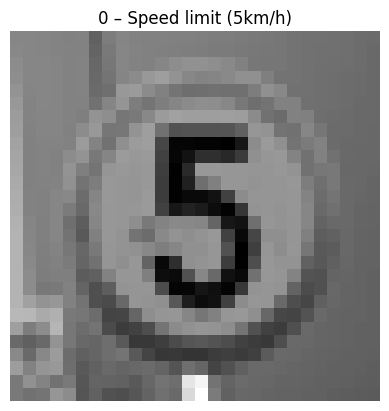

time: 163 ms (started: 2026-01-28 19:16:20 +00:00)


In [ ]:
%%script echo skipping
# load label descriptions
with open("/content/traffic_signs/labels.csv") as f:
    label_map = {int(r["ClassId"]): r["Name"] for r in csv.DictReader(f)}

# plot first image
plt.imshow(X[0].reshape(28, 28), cmap="gray")
plt.title(f"{y[0]} – {label_map[y[0]]}")
plt.axis("off")
plt.show()

## Data preprocessing


### Feature scaling

In [ ]:
%%script echo skipping
X = X.astype('float32') / 255.0

time: 16.5 ms (started: 2026-01-28 19:16:20 +00:00)


###  Select two classes (Binary Classification)

                
The original dataset contains many classes (multiclass classification).  
In this section, we convert the problem into a **binary classification** task by selecting exactly two classes (`class_1` and `class_2`) and keeping only samples that belong to those classes.


In [ ]:

%%script echo skipping
class_1 = 19
class_2 = 28

mask = (y == class_1) | (y == class_2)

X = X[mask]
y = y[mask]

y = np.where(y == class_1, 0, 1)

print(f"New X shape: {X.shape}")
print(f"New y shape: {y.shape}")

New X shape: (1014, 784)
New y shape: (1014,)
time: 4.23 ms (started: 2026-01-28 19:16:20 +00:00)



### Convert labels to one-hot (2 classes)

We set `num_classes = 2` and convert the binary labels `y` into a 2-class one-hot representation using `to_categorical`, then print the shape and an example to verify the conversion.


In [ ]:
%%script echo skipping
from keras.utils import to_categorical

num_classes = 2
y = to_categorical(y, num_classes)


print(y.shape)
print(y[0])

(1014, 2)
[1. 0.]
time: 4.18 ms (started: 2026-01-28 19:16:20 +00:00)


### Build the network layers

In this cell we define a simple baseline classifier using Keras `Sequential`.
The input is a flattened 28×28 grayscale image (784 features).


In [ ]:
%%script echo skipping
from keras.models import Sequential
from keras.layers import Flatten, Dense

model = Sequential()

model.add(Dense(128, activation='relu', input_shape=(784,)))
model.add(Dense(2, activation='softmax'))
print(model.output_shape)

(None, 2)
time: 70.7 ms (started: 2026-01-28 19:16:20 +00:00)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Build the Optimizer

In this cell we configure the optimizer (Adam with learning rate 0.001) and compile the model with `categorical_crossentropy` for 2-class one-hot labels, tracking accuracy.
The compiled model is now ready for training.


In [ ]:
%%script echo skipping
from keras.optimizers import Adam

opt = Adam(learning_rate=0.001)

model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

time: 9.67 ms (started: 2026-01-28 19:16:20 +00:00)


### Training

We split the dataset into training (80%) and test (20%) sets using `train_test_split`.
Then we train the model for 20 epochs with batch size 32, using 20% of the training data for validation and saving the training history.



In [ ]:
%%script echo skipping
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.5786 - loss: 0.7595 - val_accuracy: 0.6994 - val_loss: 0.5269
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8418 - loss: 0.4362 - val_accuracy: 0.9080 - val_loss: 0.3405
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9308 - loss: 0.2753 - val_accuracy: 0.7239 - val_loss: 0.4361
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9078 - loss: 0.2463 - val_accuracy: 0.9632 - val_loss: 0.2186
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9471 - loss: 0.1923 - val_accuracy: 0.9755 - val_loss: 0.1805
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9575 - loss: 0.1670 - val_accuracy: 0.9448 - val_loss: 0.2020
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9095 - loss: 0.2036 - val_accuracy: 0.9080 - val_loss: 0.2102
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9674 - loss: 0.1308 - val_accuracy: 0.9877 - val_loss

### Loss and Accuracy Visualization

We plot the model’s training loss and validation loss across epochs using the `history` object.
This helps us see whether the model is learning and if it starts overfitting (validation loss rising while training loss keeps falling).


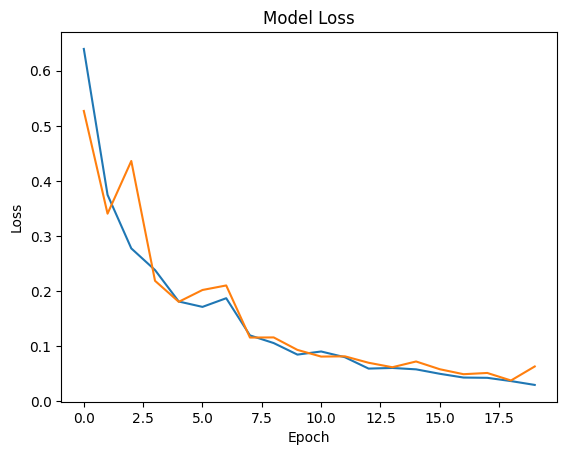

time: 122 ms (started: 2026-01-28 19:16:26 +00:00)


In [ ]:
%%script echo skipping
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.title('Model Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()

###Show on plot the accuracy during training

We plot the training accuracy and validation accuracy across epochs.
This lets us track how performance improves over time and compare generalization (validation) vs. training results.


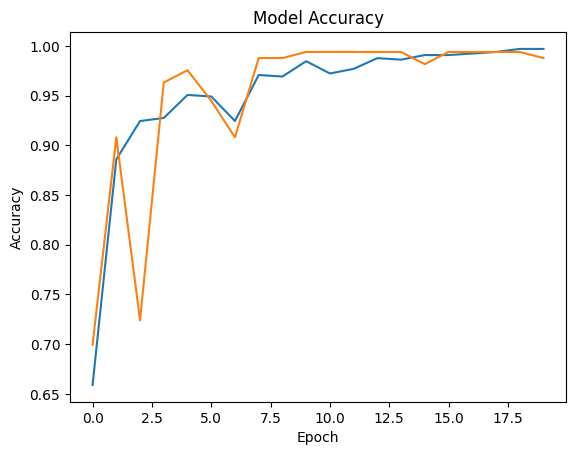

time: 146 ms (started: 2026-01-28 19:16:26 +00:00)


In [ ]:

%%script echo skipping
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.show()

### Test

We run the trained model on `X_test` to get predicted class probabilities, then convert them to class IDs using `argmax`.
We compare these predicted classes to the true labels (also converted from one-hot with `argmax`) and compute the final test accuracy with `accuracy_score`.


In [ ]:
%%script echo skipping
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)

pred_probabilities = model.predict(X_test)
y_pred_classes = np.argmax(pred_probabilities, axis=1)
y_true_classes = np.argmax(y_test, axis=1)
accuracy = accuracy_score(y_true_classes, y_pred_classes)
print(f"Final Test Accuracy: {accuracy * 100:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Final Test Accuracy: 97.54%
time: 587 ms (started: 2026-01-28 19:16:27 +00:00)


### Model Evaluation


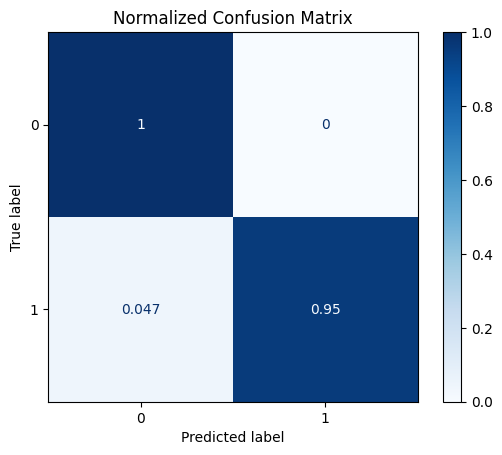

time: 145 ms (started: 2026-01-28 19:17:05 +00:00)


In [ ]:
%%script echo skipping
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import itertools

ConfusionMatrixDisplay.from_predictions(
    y_true_classes,
    y_pred_classes,
    cmap=plt.cm.Blues,
    normalize='true'
)

plt.title("Normalized Confusion Matrix")
plt.show()

The Confusion Matrix visualizes the classification performance by comparing the actual labels (rows) against the predicted labels (columns). The diagonal elements represent correct predictions, where the darker or higher values indicate better accuracy for those specific classes. Since you applied normalization (normalize='true'), the matrix displays the recall ratio (values between 0 and 1) rather than the raw count of images, showing the proportion of correctly identified samples for each class relative to the total number of samples in that class.

---
<br>


# Neural Network with Tensorflow Keras part 2 (Multiclass Classification)

### Import Libraries

In [ ]:
%%script echo skipping
%%capture
!pip install ipython-autotime
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import gdown
%load_ext autotime

time: 5.23 s (started: 2026-01-30 12:11:34 +00:00)


### Load Dataset

In [ ]:
%%script echo skipping
ROOT = Path("/content/traffic_signs/full_dataset")
X, y = [], []

for c in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    for img in c.iterdir():
        if img.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            X.append(
                np.asarray(
                    Image.open(img).convert("L").resize((28, 28)),
                    dtype=np.uint8
                ).ravel()
            )
            y.append(int(c.name))

X = np.array(X)
y = np.array(y)
print(f'Dataset shape: {X.shape}\nLabels shape: {y.shape}')

Dataset shape: (6116, 784)
Labels shape: (6116,)
time: 14.4 s (started: 2026-01-30 12:11:39 +00:00)


# Models

## Base Model





In [ ]:
%%script echo skipping
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


time: 11 ms (started: 2026-01-30 12:12:03 +00:00)


###data preparation

In this experiment we set up the dataset for **51-class classification**: we ensure labels are in the range 0–50, split into train/test, and normalize pixel values to [0,1].
Finally, we convert `y_train` and `y_test` into 51-class one-hot vectors using `to_categorical`.


In [ ]:
%%script echo skipping

print("Starting Base Model...")

y_adjusted = y - 1 if y.max() == 51 else y
X_train, X_test, y_train, y_test = train_test_split(X, y_adjusted, test_size=0.2, random_state=42)

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, 51)
y_test_cat = to_categorical(y_test, 51)

Starting Base Model...
time: 19.6 ms (started: 2026-01-30 12:12:07 +00:00)



### Model Architecture

We build a deeper fully-connected (MLP) network for 51-class classification: multiple ReLU dense layers followed by a 51-unit softmax output layer.
Then we compile it with Adam and `categorical_crossentropy`, tracking accuracy.






In [ ]:

%%script echo skipping

model_1 = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(128, activation='relu'),
    Dense(96, activation='relu'),
    Dense(64, activation='relu'),
    Dense(51, activation='softmax')
])

model_1.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


time: 3.17 s (started: 2026-01-30 12:12:12 +00:00)


### Training

We train `model_1` on the training set for 30 epochs (batch size 64), while holding out 15% of the training data for validation.
The training history (`history_1`) stores loss/accuracy curves for later analysis.


In [ ]:
%%script echo skipping

print("Training...")
history_1 = model_1.fit(X_train, y_train_cat,
                        epochs=30,
                        batch_size=64,
                        validation_split=0.15,
                        verbose=1)


Training...
Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.0886 - loss: 3.7395 - val_accuracy: 0.1417 - val_loss: 3.3692
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1742 - loss: 3.2564 - val_accuracy: 0.2139 - val_loss: 2.9413
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2498 - loss: 2.8298 - val_accuracy: 0.3583 - val_loss: 2.5257
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3900 - loss: 2.3383 - val_accuracy: 0.4223 - val_loss: 2.1975
Epoch 5/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4522 - loss: 2.0128 - val_accuracy: 0.4809 - val_loss: 1.9552
Epoch 6/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5159 - loss: 1.7662 - val_accuracy: 0.5095 - val_loss: 1.8228
Epoch 7/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5743 - loss: 1.5630 - val_accuracy: 0.5804 - val_loss: 1.6270
Epoch 8/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6100 - loss: 1.4518 - val_accuracy: 0.600

###Visualisation

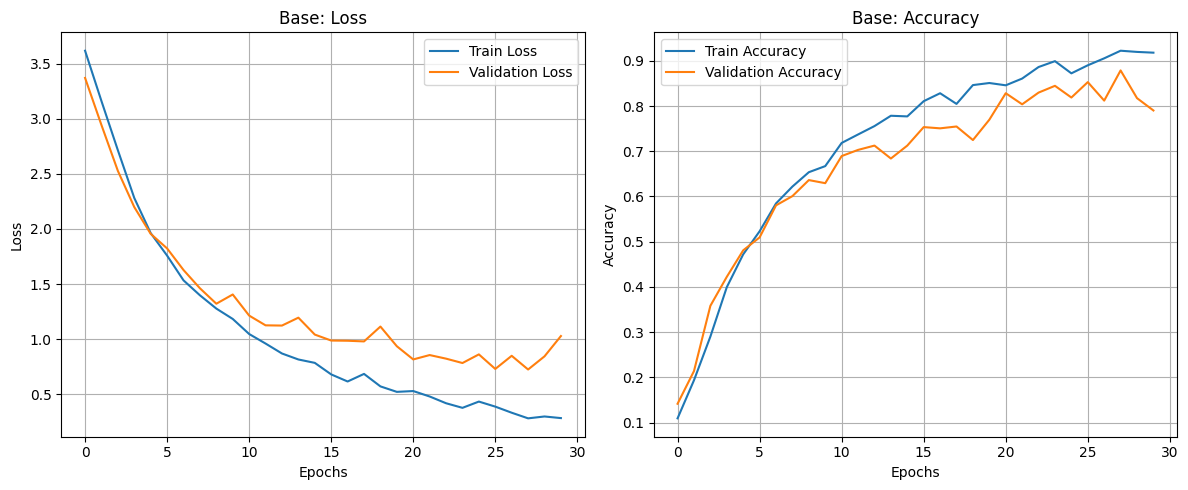

time: 303 ms (started: 2026-01-30 12:12:28 +00:00)


In [ ]:
%%script echo skipping

plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history_1.history['loss'], label='Train Loss')
plt.plot(history_1.history['val_loss'], label='Validation Loss')
plt.title('Base: Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(history_1.history['accuracy'], label='Train Accuracy')
plt.plot(history_1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Base: Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

###Evaluation

In [ ]:
%%script echo skipping

print("\nEvaluation on Test Set:")
loss_1, acc_1 = model_1.evaluate(X_test, y_test_cat, verbose=0)
print(f"Final Test Accuracy: {acc_1 * 100:.2f}%")

print("\nClassification Report:")
y_pred_1 = np.argmax(model_1.predict(X_test), axis=1)


Evaluation on Test Set:
Final Test Accuracy: 81.21%

Classification Report:
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
time: 1.79 s (started: 2026-01-30 12:12:28 +00:00)


In this experiment, we established a Baseline Model to set a performance benchmark for the classification task. The architecture is a standard Fully Connected Network consisting of four hidden layers with 128, 128, 96, and 64 neurons, respectively, all utilizing ReLU activation to introduce non-linearity. The network accepts a flattened input of 784 pixels and concludes with a 51-neuron Softmax output layer to predict the probability distribution across classes. We selected the Adam optimizer for its general efficiency and Categorical Crossentropy as the loss function suitable for multi-class problems. The training was conducted for 30 epochs with a batch size of 64, a configuration chosen to balance training speed with gradient stability, serving as a naive reference point for future architectural and hyperparameter improvements.

## Experiment number 1

Experiment 1: Architecture Modification (High Capacity)

###data preparation

This cell prepares the data for Experiment 1 by ensuring labels are in the range 0–50 (shifting them down by 1 if needed), splitting the dataset into train/test sets, and normalizing pixel values to [0,1]. Then it one-hot encodes the labels into 51 classes and reshapes the images into 784-length vectors to fit a fully connected (dense) network.

In [ ]:
%%script echo skipping
print("Starting Experiment 1...")

if 'y' in globals() and y.max() == 51:
    y = y - 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


y_train_cat = to_categorical(y_train, 51)
y_test_cat = to_categorical(y_test, 51)


X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))

Starting Experiment 1...
time: 14.2 ms (started: 2026-01-27 19:44:26 +00:00)


### Model Architecture

 We introduce a "High Capacity" architecture to capture complex features.
 Structure: 1024 -> 512 -> 512 -> 256 -> Output

In [ ]:
%%script echo skipping
from tensorflow.keras.layers import Dense, Activation, Input

model_exp1 = Sequential()

model_exp1.add(Input(shape=(784,)))


model_exp1.add(Dense(1024))
model_exp1.add(Activation('relu'))


model_exp1.add(Dense(512))
model_exp1.add(Activation('relu'))


model_exp1.add(Dense(512))
model_exp1.add(Activation('relu'))


model_exp1.add(Dense(256))
model_exp1.add(Activation('relu'))


model_exp1.add(Dense(51, activation='softmax'))


model_exp1.compile(loss='categorical_crossentropy',
                   optimizer='adam',
                   metrics=['accuracy'])


time: 120 ms (started: 2026-01-27 19:46:00 +00:00)


###Training

In [ ]:
%%script echo skipping

print("Training ...")
history_exp1 = model_exp1.fit(
    X_train, y_train_cat,
    epochs=30,
    batch_size=64,
    validation_split=0.15,
    verbose=1
)

Training ...
Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.1077 - loss: 3.6088 - val_accuracy: 0.2207 - val_loss: 3.0706
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2968 - loss: 2.7058 - val_accuracy: 0.3856 - val_loss: 2.3099
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4483 - loss: 2.0408 - val_accuracy: 0.4959 - val_loss: 1.9634
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5356 - loss: 1.6289 - val_accuracy: 0.5300 - val_loss: 1.7348
Epoch 5/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6246 - loss: 1.2989 - val_accuracy: 0.5995 - val_loss: 1.5151
Epoch 6/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6752 - loss: 1.1546 - val_accuracy: 0.6717 - val_loss: 1.2062
Epoch 7/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7134 - loss: 1.0121 - val_accuracy: 0.6894 - val_loss: 1.1128
Epoch 8/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7829 - loss: 0.7803 - val_accuracy: 0.69

###Visualisation

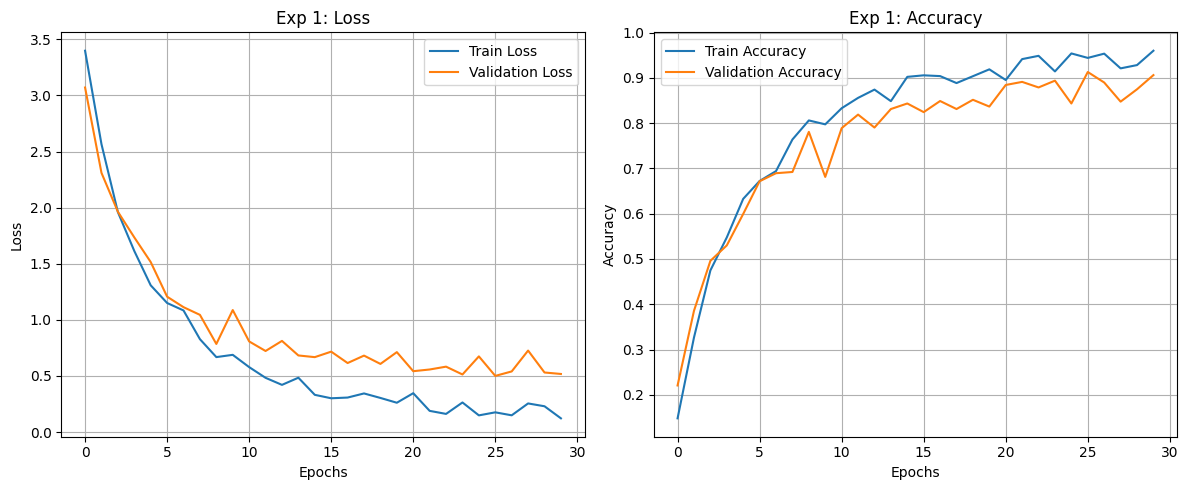

time: 326 ms (started: 2026-01-27 19:46:55 +00:00)


In [ ]:
%%script echo skipping

plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(history_exp1.history['loss'], label='Train Loss')
plt.plot(history_exp1.history['val_loss'], label='Validation Loss')
plt.title('Exp 1: Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)
plt.plot(history_exp1.history['accuracy'], label='Train Accuracy')
plt.plot(history_exp1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Exp 1: Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

###Evaluation

In [ ]:
%%script echo skipping

print("\nEvaluating Experiment 1...")
loss_1, acc_1 = model_exp1.evaluate(X_test, y_test_cat, verbose=0)
print(f"Experiment 1 Test Accuracy: {acc_1 * 100:.2f}%")


Evaluating Experiment 1...
Experiment 1 Test Accuracy: 90.44%
time: 1.18 s (started: 2026-01-27 19:46:59 +00:00)


In this experiment, we focused exclusively on architectural modifications to assess the impact of increased model capacity on performance. We designed a Deep Neural Network with a significantly wider and deeper structure than the baseline, comprising four hidden layers with 1024, 512, 512, and 256 neurons, respectively. This "High Capacity" architecture was chosen to project the input data into a higher-dimensional space, allowing the network to capture more complex, non-linear features and hierarchical patterns within the traffic sign images. All hidden layers utilize the ReLU activation function to facilitate efficient training. We employed the Adam optimizer for its adaptive learning capabilities and trained the model for 30 epochs with a batch size of 64; these hyperparameters were kept standard to ensure that any observed improvements in accuracy could be attributed primarily to the structural expansion of the network rather than advanced tuning strategies.

## Experiment number 2

Experiment 2: Hyper parameters tuning

###data preparation

In [ ]:
%%script echo skipping
from tensorflow.keras.callbacks import ModelCheckpoint

print("\nStarting Experiment 2 ...")



if 'y' in globals() and y.max() == 51:
    y = y - 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


y_train_cat = to_categorical(y_train, 51)
y_test_cat = to_categorical(y_test, 51)


X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))



Starting Experiment 2 ...
time: 15.2 ms (started: 2026-01-27 20:19:44 +00:00)


###Model Architecture

In [ ]:
%%script echo skipping

model_exp2 = Sequential()
model_exp2.add(Input(shape=(784,)))
model_exp2.add(Dense(1024))
model_exp2.add(Activation('relu'))
model_exp2.add(Dense(512))
model_exp2.add(Activation('relu'))
model_exp2.add(Dense(512))
model_exp2.add(Activation('relu'))
model_exp2.add(Dense(256))
model_exp2.add(Activation('relu'))
model_exp2.add(Dense(51, activation='softmax'))

time: 90.3 ms (started: 2026-01-27 20:19:46 +00:00)


###Hyperparameter Tuning

from 0.001 to 0.0001 to allow for smaller and more precise weight updates, preventing the model from overshooting the optimal solution and ensuring a more stable convergence.

In [ ]:
%%script echo skipping

optimizer = Adam(learning_rate=0.0001) .

model_exp2.compile(loss='categorical_crossentropy',
                   optimizer=optimizer,
                   metrics=['accuracy'])


time: 6.89 ms (started: 2026-01-27 20:19:47 +00:00)


###Training

We increased the number of epochs from 30 to 50 to compensate for the reduced learning rate, ensuring the model has enough iterations to fully converge despite taking smaller steps.

In [ ]:
%%script echo skipping

print("Training Optimized Model ...")
history_exp2 = model_exp2.fit(
    X_train, y_train_cat,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    verbose=1
)

Training Optimized Model ...
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.0896 - loss: 3.6817 - val_accuracy: 0.2371 - val_loss: 3.1358
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2776 - loss: 2.9978 - val_accuracy: 0.4169 - val_loss: 2.5258
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4447 - loss: 2.3240 - val_accuracy: 0.5136 - val_loss: 2.0838
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5307 - loss: 1.9568 - val_accuracy: 0.5422 - val_loss: 1.8166
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5888 - loss: 1.6631 - val_accuracy: 0.5858 - val_loss: 1.6339
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6567 - loss: 1.3718 - val_accuracy: 0.6376 - val_loss: 1.5051
Epoch 7/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6935 - loss: 1.2381 - val_accuracy: 0.6240 - val_loss: 1.4716
Epoch 8/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7217 - l

###Visualization

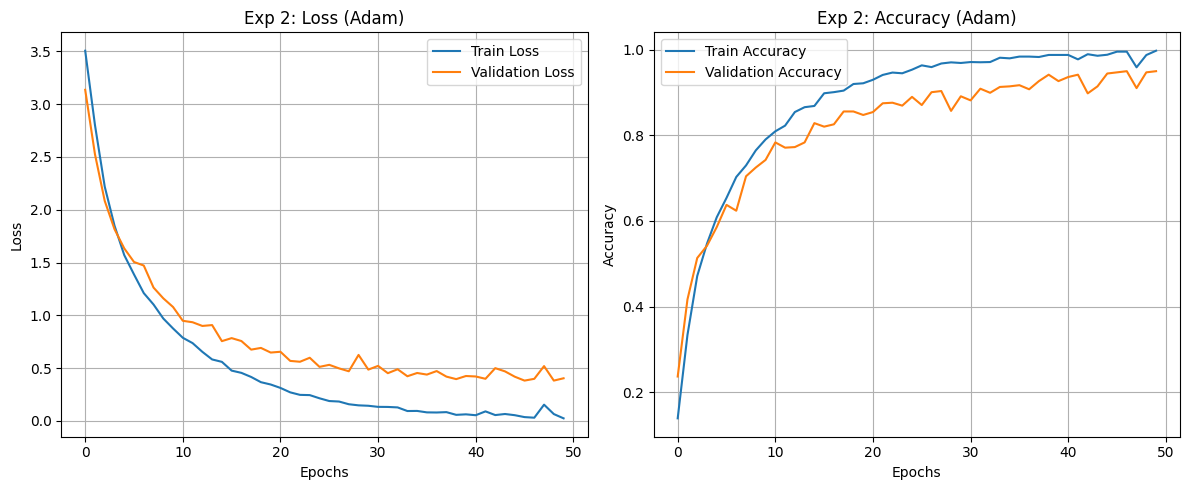

time: 283 ms (started: 2026-01-27 20:20:17 +00:00)


In [ ]:
%%script echo skipping


plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(history_exp2.history['loss'], label='Train Loss')
plt.plot(history_exp2.history['val_loss'], label='Validation Loss')
plt.title('Exp 2: Loss (Adam)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(); plt.grid(True)


plt.subplot(1, 2, 2)
plt.plot(history_exp2.history['accuracy'], label='Train Accuracy')
plt.plot(history_exp2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Exp 2: Accuracy (Adam)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

###Evaluation

In [ ]:
%%script echo skipping
print("\nEvaluating the currently trained model (from memory)...")
loss, acc = model_exp2.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nExperiment 2 Test Accuracy (Current Run): {acc * 100:.2f}%")



Evaluating the currently trained model (from memory)...

Experiment 2 Test Accuracy (Current Run): 94.12%
time: 460 ms (started: 2026-01-27 20:20:18 +00:00)


In this experiment, we focused on optimizing the training process through hyperparameter tuning without altering the model's capacity. We reduced the learning rate from 0.001 to 0.0001 to enable smaller, more precise weight adjustments, aiming to improve convergence stability and avoid overshooting the optimal solution. To compensate for this slower learning pace, we increased the training duration from 30 to 50 epochs, ensuring the model had sufficient time to learn. Additionally, we decreased the batch size from 64 to 32; this smaller batch size provides more frequent updates and introduces beneficial noise that helps the model escape local minima and generalize better to new data.

## Save Trained model Model Block(saving the best model)


In [ ]:
%%script echo skipping

from tensorflow.keras.models import load_model
import os
from google.colab import files


files.download(final_filename)

temp_file = 'temp_best_weights.keras'
final_filename = 'final_best_model.keras'

if os.path.exists(temp_file):
    print(f"Loading best weights from temporary file: {temp_file}...")
    best_model = load_model(temp_file)

    print(f"Saving final model to: {final_filename}...")
    best_model.save(final_filename)
    print("Success! The best model has been saved permanently.")

else:
    print("Error: Temporary checkpoint file not found. Did you run Experiment 2?")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading best weights from temporary file: temp_best_weights.keras...
Saving final model to: final_best_model.keras...
Success! The best model has been saved permanently.
time: 259 ms (started: 2026-01-27 20:23:15 +00:00)


### Test Environment (of part 2 only)


Download Pre-Trained Model Block



In [ ]:
import os
import gdown
from tensorflow.keras.models import load_model


file_id = '14M4JkZcmpdfPrQv8cCXPlysIzCoPMbxr'

url = f'https://drive.google.com/uc?id={file_id}'
output = 'final_best_model.keras'

explainer_file_id = '1pmlAakpndKJysYOpP8RMWqWKzIZK5xak'
explainer_output = 'explainer.md'

if not os.path.exists(output):
    print(f"Downloading model from Drive (ID: {file_id})...")
    gdown.download(url, output, quiet=False)
else:
    print("Model file found locally. Skipping download.")

if not os.path.exists(explainer_output):
    print(f"Downloading Explainer from Drive (ID: {explainer_file_id})...")
    gdown.download(f'https://drive.google.com/uc?id={explainer_file_id}', explainer_output, quiet=False)
else:
    print("Explainer file found locally. Skipping download.")

print("Loading model for evaluation...")
try:
    final_model = load_model(output)
    print("Success! Final model loaded.")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Check: Did you update the file_id correctly and set permission to 'Anyone with link'?")

Model file found locally. Skipping download.


Since the model was trained on zero-indexed labels (0-50) while the original dataset classes are one-indexed (1-51), we add 1 to the model's predicted index to retrieve the correct class label.

--- Test Environment ---
Instruction: Please upload a single .npy file (28x28 image).


Saving 45.npy to 45.npy

Model Prediction: Class 45


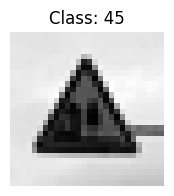

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def test_environment_upload():
    print("--- Test Environment ---")
    print("Instruction: Please upload a single .npy file (28x28 image).")


    if 'final_model' not in globals():
        print("Error: Model not loaded. Please run the download block above first.")
        return

    uploaded = files.upload()

    for filename in uploaded.keys():
        if not filename.endswith('.npy'):
            print(f"Skipping {filename}: Not a .npy file.")
            continue

        try:
            image_data = np.load(filename)
            input_vector = image_data.reshape(1, 784).astype('float32')


            if input_vector.max() > 1.0:
                input_vector /= 255.0


            prediction_probs = final_model.predict(input_vector, verbose=0)
            raw_index = np.argmax(prediction_probs)


            predicted_class = raw_index + 1


            print(f"\nModel Prediction: Class {predicted_class}")

            plt.figure(figsize=(2, 2))
            plt.imshow(image_data, cmap='gray')
            plt.title(f"Class: {predicted_class}")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Error processing file: {e}")


test_environment_upload()